# hexgrid-maker showcase: 500 m hexagons over five Paris landmarks

Question: how many 500 m hexagons cover the area spanned by five Paris landmarks, and which cells hold a landmark?

Data: `showcase/data/paris_landmarks.geojson` (positions from OpenStreetMap, ODbL).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from pyproj import Geod
from shapely.geometry import shape

from hexgrid_maker import hex_grid, load_geometry

root = Path.cwd()
if not (root / 'showcase').exists():  # notebook run from inside showcase/
    root = root.parent
path = root / 'showcase' / 'data' / 'paris_landmarks.geojson'
hull = load_geometry(path)  # convex hull of the points, lon/lat (EPSG:4326)
print(hull.geom_type, [round(v, 4) for v in hull.bounds])

Polygon [2.2945, 48.853, 2.3499, 48.8867]


In [2]:
grid = hex_grid(hull, 500, orientation='flat')  # edge length in metres, laid out in UTM 31N
cells = grid['features']
print(len(cells), 'cells')
print(cells[0]['properties'])

26 cells
{'id': 0, 'col': 0, 'row': 1, 'area_m2': 649996.2}


In [3]:
import json

landmarks = json.loads(path.read_text(encoding='utf-8'))['features']
points = [(f['properties']['name'], shape(f['geometry'])) for f in landmarks]
for c in cells:
    geom = shape(c['geometry'])
    names = [n for n, p in points if geom.covers(p)]
    c['properties']['landmarks'] = ', '.join(names)
    c['properties']['n_landmarks'] = len(names)

print('cells with a landmark:', sum(c['properties']['n_landmarks'] > 0 for c in cells))
print('grid area km2: %.2f' % (sum(c['properties']['area_m2'] for c in cells) / 1e6))
print('hull area km2: %.2f' % (abs(Geod(ellps='WGS84').geometry_area_perimeter(hull)[0]) / 1e6))
print()
print('%-4s %-4s %-4s %-10s %s' % ('id', 'col', 'row', 'area_m2', 'landmarks'))
for c in cells:
    p = c['properties']
    if p['n_landmarks']:
        print('%-4d %-4d %-4d %-10.1f %s' % (p['id'], p['col'], p['row'], p['area_m2'], p['landmarks']))

cells with a landmark: 5
grid area km2: 16.90
hull area km2: 10.46

id   col  row  area_m2    landmarks
0    0    1    649996.2   Eiffel Tower
2    0    3    649996.2   Arc de Triomphe
16   4    1    650001.0   Louvre
24   5    4    650002.2   Sacre-Coeur
25   6    0    650003.3   Notre-Dame


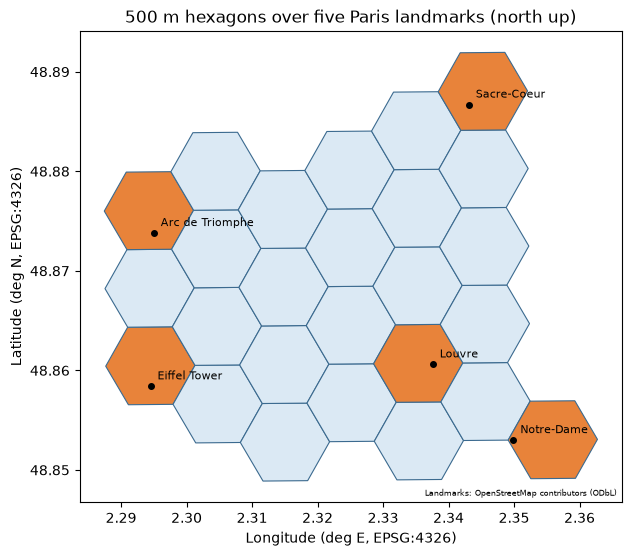

In [4]:
import math

fig, ax = plt.subplots(figsize=(7, 7))
for c in cells:
    hit = c['properties']['n_landmarks'] > 0
    ax.add_patch(Polygon(c['geometry']['coordinates'][0], closed=True,
                         fc='#e8833a' if hit else '#dbe9f4', ec='#3b6a8f', lw=0.8))
for name, p in points:
    ax.plot(p.x, p.y, 'o', color='k', ms=4)
    ax.annotate(name, (p.x, p.y), xytext=(5, 5), textcoords='offset points', fontsize=8)
ax.autoscale_view()
ax.set_aspect(1 / math.cos(math.radians(48.86)))
ax.set_xlabel('Longitude (deg E, EPSG:4326)')
ax.set_ylabel('Latitude (deg N, EPSG:4326)')
ax.set_title('500 m hexagons over five Paris landmarks (north up)')
ax.text(0.99, 0.01, 'Landmarks: OpenStreetMap contributors (ODbL)', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=6)
plt.show()